# nongaussian-surfaces: quick tour

Generate rough surfaces with a prescribed **height distribution** (rms, skewness, kurtosis) and **spatial structure** (correlation lengths, roughness exponent), then inspect them with static or interactive plots.

Credits: algorithm by V. Constantoudis after Yang et al. (2014); Johnson fitting by Dave (2021) and M. Pierini; package by S. Korsak.

In [1]:
# !pip install "nongaussian-surfaces[interactive]"
%matplotlib inline
from nongauss import generate_surface, print_report, plots, moments

## 1. Generate a surface

`skewness` > 0 gives sharp peaks over a flat floor, `kurtosis` > 3 gives rare tall spikes, `corlength_*` sets feature size in pixels, `alpha` sets roughness (small = jagged).

In [2]:
res = generate_surface(N=256, rms=3, skewness=1, kurtosis=4,
                       corlength_x=12, corlength_y=12, alpha=0.8, seed=7)
res.z.shape, res.j_type   # heights (min = 0) and the fitted Johnson family

((256, 256), 'SB')

Requested vs. achieved statistics (the mean is not a parameter: the surface is shifted to min = 0).

In [3]:
print_report(res)

metric      requested   achieved    error
-----------------------------------------
mean            0.000      5.236      n/a
rms             3.000      3.000    -0.0%
skewness        1.000      1.009    +0.9%
kurtosis        4.000      4.069    +1.7%

Johnson type : SB
Corr. lengths: x=12, y=12, alpha=0.8
Grid         : 256 x 256
(mean n/a: surface is shifted so min height = 0)


## 2. Static plots

Every `plots.plot_*` function returns a matplotlib figure with at most two panels. The left surface is the Gaussian scaffold that sets *where* hills are; the right one has the requested height distribution.

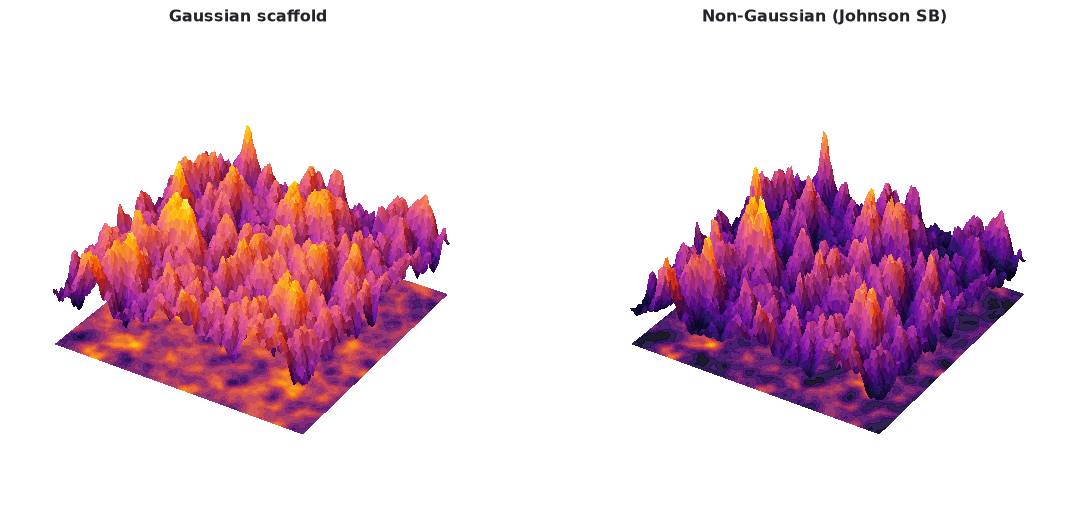

In [4]:
plots.plot_surfaces(res);

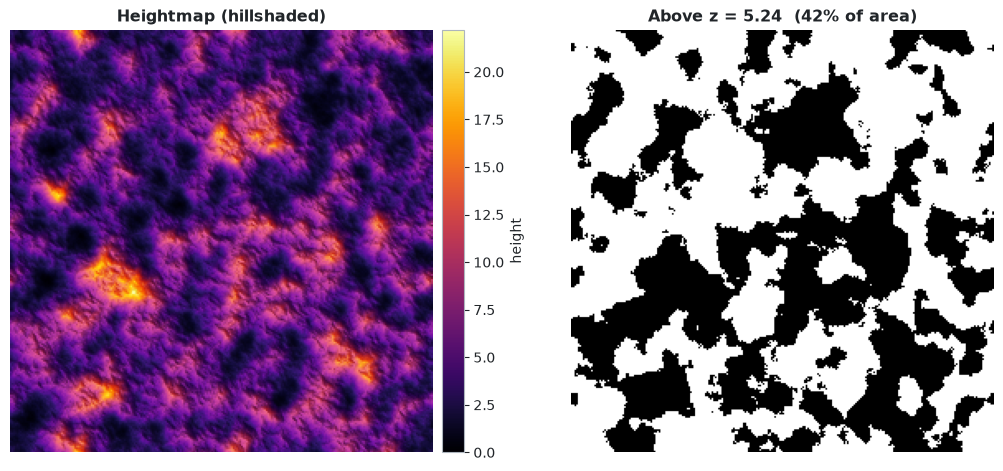

In [5]:
plots.plot_heightmap_mask(res);   # heightmap and the area above the mean height

The histogram follows the fitted Johnson curve; a straight Q-Q line means a perfect match.

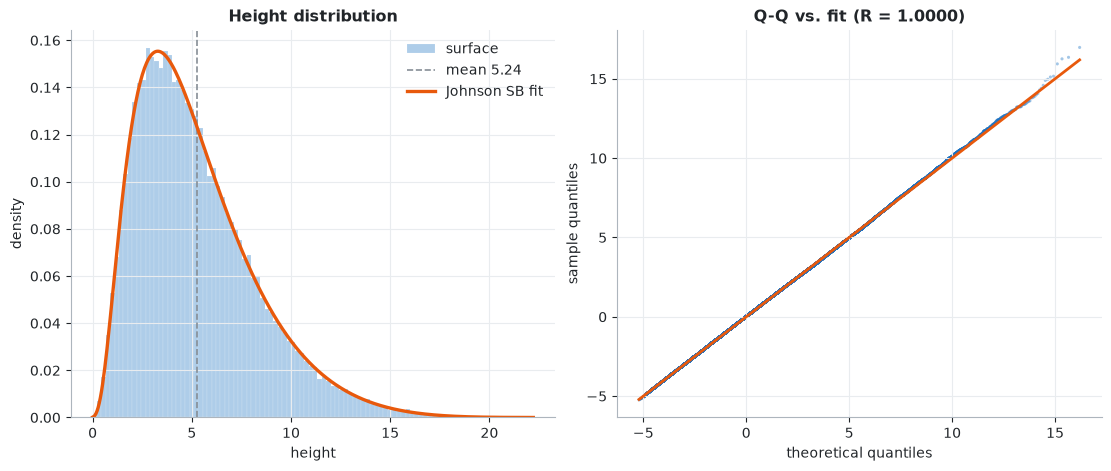

In [6]:
plots.plot_distribution(res);

## 3. Effect of a parameter

Same seed, only skewness changes: negative gives deep pits, positive gives sharp peaks.

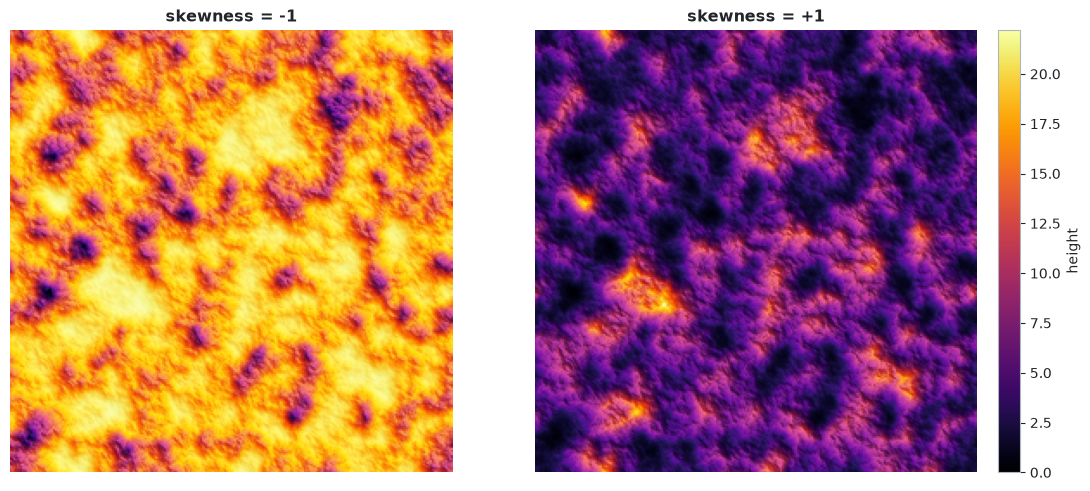

In [7]:
neg = generate_surface(N=256, rms=3, skewness=-1, kurtosis=4, corlength_x=12, corlength_y=12, alpha=0.8, seed=7)
plots.plot_compare(neg, res, ['skewness = -1', 'skewness = +1']);

## 4. Interactive plots

Add `interactive=True` to any plot to get a Plotly figure you can rotate, zoom and hover over.

In [8]:
plots.plot_surfaces(res, interactive=True)

In [9]:
plots.plot_spectrum(res, interactive=True)   # power spectrum: energy per spatial frequency

A slider over one parameter (all surfaces share the seed):

In [10]:
from nongauss import interactive
interactive.explorer('skewness', (-1.5, -1, 0, 1, 1.5), N=64, kurtosis=4)

## 5. Which Johnson family?

The (skewness, kurtosis) pair decides the distribution family; kurtosis can never be below 1 + skewness².

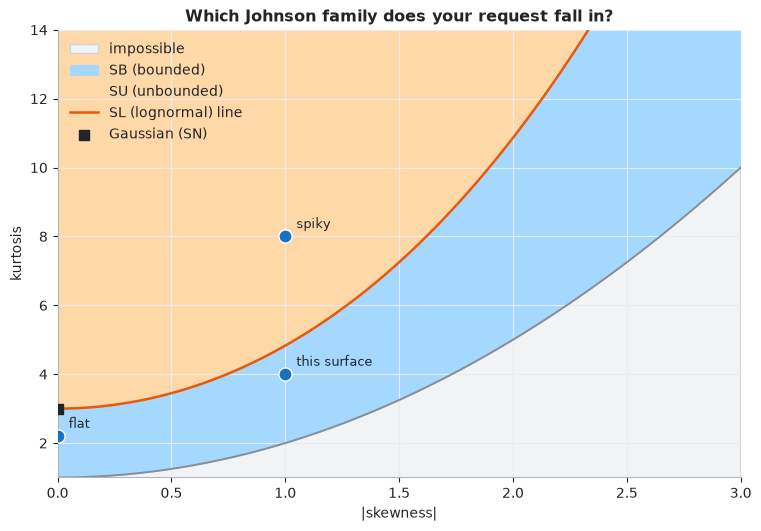

In [11]:
plots.plot_feasibility([(1, 4, 'this surface'), (0, 2.2, 'flat'), (1, 8, 'spiky')]);

## 6. Statistics without plots

In [12]:
from nongauss import hhcf_1d, abbott_curve

mean, std, skew, kurt = moments(res.z)
g = hhcf_1d(res.z, axis=1)         # height-height correlation along x
pct, h = abbott_curve(res.z)       # bearing-area curve: % of area above each height
print(f'rms={std:.2f} skew={skew:.2f} kurt={kurt:.2f}; G(r=10)={g[10]:.2f}')

rms=3.00 skew=1.01 kurt=4.07; G(r=10)=3.10


Save any figure with `plots.save(fig, 'name.png')` (or `.html` for interactive). Full docs: see the `mkdocs/` folder.